# CareerMind — Agent 2: Salary Prediction (Regression)
**Course:** 24CSE0316 — Artificial Intelligence & Machine Learning

**Workflow:** Load data → Validate → Build salary dataset → Feature engineering → EDA and skewness → Regression algorithms → Compare MAE/MSE/RMSE/R² → Select best model → Save pipeline.

**Target:** `average_annual_salary_inr` (annual INR).

R² is a regression metric, not classification accuracy. All metrics are evaluated on a held-out test set.

## 1. Setup and Load Dataset

In [1]:

# ============================================================
# CAREERMIND - COMMON SETUP FOR ALL THREE AGENTS
# ============================================================

import os
import re
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

warnings.filterwarnings("ignore")

# Original shared CareerMind folder
BASE = "/content/drive/.shortcut-targets-by-id/1IxCYpLimAWYB151hnChx-TeglPEVDRrE/CareerMind"

# Data directories
DATA_DIR = os.path.join(BASE, "Data")
RAW_DIR = os.path.join(DATA_DIR, "Raw")
CLEAN_DIR = os.path.join(DATA_DIR, "Cleaned")
PROCESSED_DIR = os.path.join(DATA_DIR, "Processed")

# Model and result directories
MODEL_DIR = os.path.join(BASE, "Models")
RESULTS_DIR = os.path.join(BASE, "Results")

# Agent-specific directories
CLASSIFIER_DIR = os.path.join(MODEL_DIR, "Classifier")
PREDICTOR_DIR = os.path.join(MODEL_DIR, "Predictor")
GROUPING_DIR = os.path.join(MODEL_DIR, "Grouping")

# Create output directories
for folder in [
    PROCESSED_DIR, RESULTS_DIR,
    CLASSIFIER_DIR, PREDICTOR_DIR, GROUPING_DIR
]:
    os.makedirs(folder, exist_ok=True)

# Load cleaned V2 dataset
DATA_PATH = os.path.join(
    CLEAN_DIR,
    "careermind_master_dataset_v2.csv"
)

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

print("=" * 55)
print("CAREERMIND - DATASET LOADED")
print("=" * 55)
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Columns:", df.columns.tolist())

display(df.head(3))


Mounted at /content/drive
Upload careermind_master_dataset.csv


Saving careermind_master_dataset_v2.csv to careermind_master_dataset_v2.csv
Dataset loaded: (6000, 15)


,job_id,job_title,job_description,skills,experience_min_years,experience_max_years,experience_midpoint_years,experience_level,location,job_category,minimum_annual_salary_inr,maximum_annual_salary_inr,average_annual_salary_inr,currency,salary_period
0,CM000760,Engineer,Collaborates with business and technical teams...,"NumPy, Project Coordination",7,11,9.0,Senior,Hyderabad,Data Science & AI,2420000,2920000,2670000,INR,Annual
1,CM002306,Operations Associate,"Reviews workflows, prepares status updates, su...","Linux, Firewalls, Python, Data Analysis, Tally",4,7,5.5,Mid Level,Gurugram,Cybersecurity,900000,1180000,1040000,INR,Annual
2,CM002285,Security Analyst,"Collects and reviews information, identifies i...","Incident Response, SIEM, Python, Communication...",4,7,5.5,Mid Level,Jaipur,Cybersecurity,970000,1250000,1110000,INR,Annual
3,CM002352,Developer,"Helps plan and execute team activities, checks...","SIEM, Network Security, Firewalls, Python, Pro...",1,2,1.5,Junior,Ahmedabad,Cybersecurity,590000,730000,660000,INR,Annual
4,CM003961,Technical Analyst,plans digital campaigns and evaluates audience...,"Social Media, Excel, Problem Solving",1,2,1.5,Junior,Bengaluru,Marketing,450000,570000,510000,INR,Annual


## 2. Validate Dataset and Build Regression Dataset

In [3]:
# Dataset quality checks
print("Rows, columns:", df.shape)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate full rows:", df.duplicated().sum())
print("Duplicate job IDs:", df["job_id"].duplicated().sum())
print("\nData types:\n", df.dtypes)
assert df["job_id"].is_unique, "Duplicate job_id values found."
assert df.isna().sum().sum() == 0, "Missing values found. Inspect before training."
assert set(df["currency"].astype(str).str.upper().unique()) == {"INR"}, "Unexpected currency found."
assert set(df["salary_period"].astype(str).str.lower().unique()) == {"annual"}, "Salary period is not consistently annual."
assert (df["minimum_annual_salary_inr"] <= df["maximum_annual_salary_inr"]).all()
assert np.allclose(
    df["average_annual_salary_inr"],
    (df["minimum_annual_salary_inr"] + df["maximum_annual_salary_inr"]) / 2
), "Average salary does not match min/max midpoint."
print("\nAll initial dataset checks passed.")

Rows, columns: (6000, 15)

Missing values:
 job_id                       0
job_title                    0
job_description              0
skills                       0
experience_min_years         0
experience_max_years         0
experience_midpoint_years    0
experience_level             0
location                     0
job_category                 0
minimum_annual_salary_inr    0
maximum_annual_salary_inr    0
average_annual_salary_inr    0
currency                     0
salary_period                0
dtype: int64

Duplicate full rows: 0
Duplicate job IDs: 0

Data types:
 job_id                        object
job_title                     object
job_description               object
skills                        object
experience_min_years           int64
experience_max_years           int64
experience_midpoint_years    float64
experience_level              object
location                      object
job_category                  object
minimum_annual_salary_inr      int64
maximum_annu

In [4]:
reg = df.copy()
reg = reg[
    (reg["minimum_annual_salary_inr"] > 0) &
    (reg["maximum_annual_salary_inr"] > 0) &
    (reg["minimum_annual_salary_inr"] <= reg["maximum_annual_salary_inr"]) &
    (reg["average_annual_salary_inr"] > 0)
].copy()

print("Regression rows:", len(reg))
print(reg["average_annual_salary_inr"].describe().round(0))
print("Salary currency:", reg["currency"].unique())
print("Salary period:", reg["salary_period"].unique())

Regression rows: 6000
count       6000.0
mean      887620.0
std       449986.0
min       220000.0
25%       550000.0
50%       780000.0
75%      1100000.0
max      3290000.0
Name: average_annual_salary_inr, dtype: float64
Salary currency: ['INR']
Salary period: ['Annual']


## 3. Feature Engineering

In [5]:
# Construct text feature from job title, description and skills.
reg["job_text"] = (
    reg["job_title"].fillna("").astype(str) + " " +
    reg["job_description"].fillna("").astype(str) + " " +
    reg["skills"].fillna("").astype(str)
)
# Midpoint and range are provided in the master dataset; recompute to verify consistency.
reg["experience_midpoint"] = (
    reg["experience_min_years"] + reg["experience_max_years"]
) / 2
reg["experience_range"] = (
    reg["experience_max_years"] - reg["experience_min_years"]
)
reg["is_zero_experience"] = (
    (reg["experience_min_years"] == 0) &
    (reg["experience_max_years"] == 0)
).astype(int)

assert np.allclose(reg["experience_midpoint"], reg["experience_midpoint_years"])
display(reg[["job_title","location","experience_midpoint","experience_range",
             "average_annual_salary_inr"]].head())

,job_title,location,experience_midpoint,experience_range,average_annual_salary_inr
0,Engineer,Hyderabad,9.0,4,2670000
1,Operations Associate,Gurugram,5.5,3,1040000
2,Security Analyst,Jaipur,5.5,3,1110000
3,Developer,Ahmedabad,1.5,1,660000
4,Technical Analyst,Bengaluru,1.5,1,510000


## 4. Exploratory Data Analysis — Salary Distribution and Skewness

Mean salary: ₹ 887,620
Median salary: ₹ 780,000
Standard deviation: ₹ 449,986
Skewness: 1.352
Minimum: ₹ 220,000
Maximum: ₹ 3,290,000


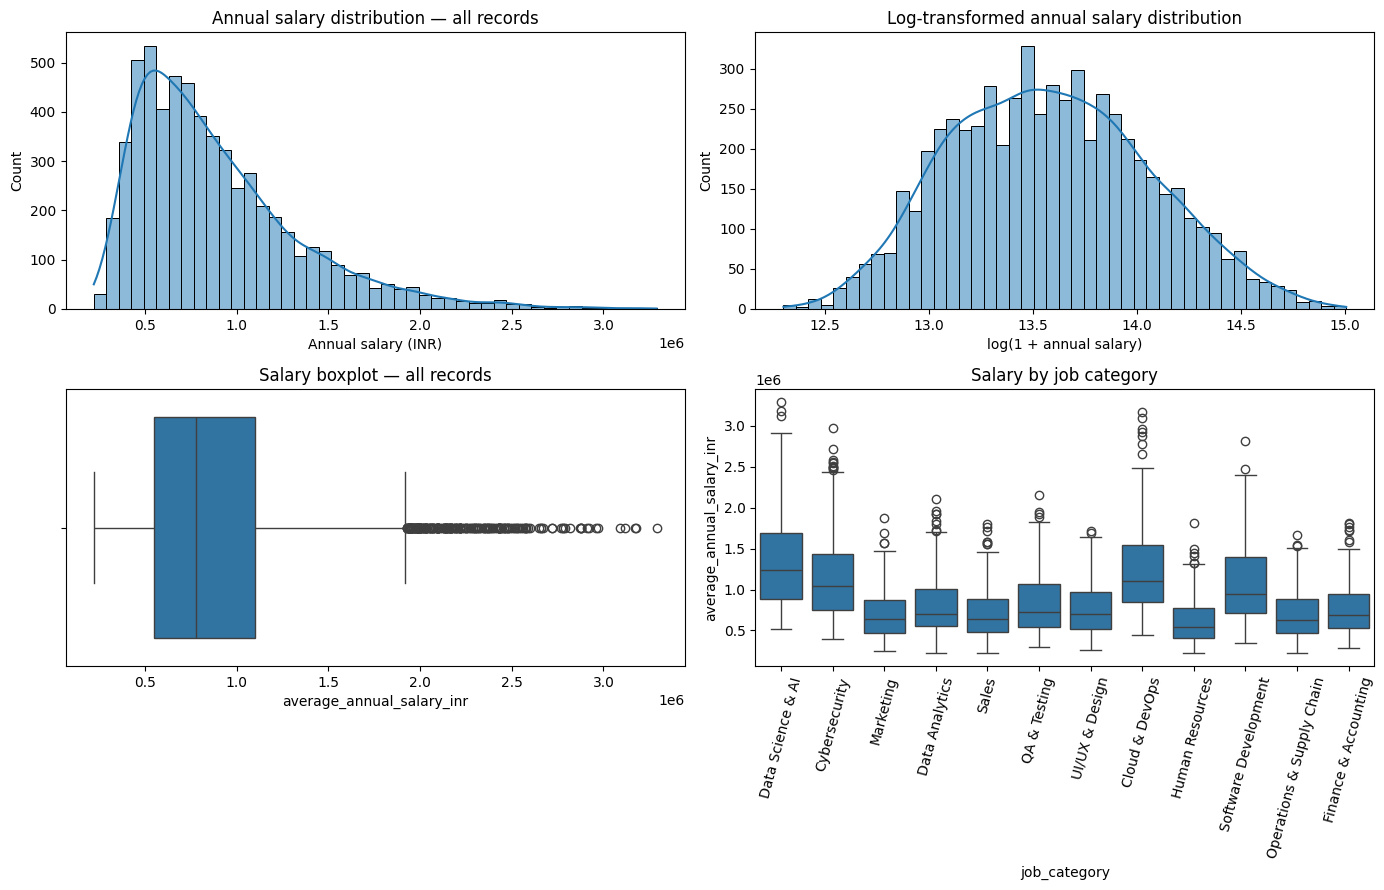


Salary percentiles:


,annual_salary_inr
0.00,220000.0
0.25,550000.0
0.50,780000.0
0.75,1100000.0
0.90,1500000.0
0.95,1790000.0
0.99,2390100.0
1.00,3290000.0


In [6]:
salary = reg["average_annual_salary_inr"]
print("Mean salary: ₹", f"{salary.mean():,.0f}")
print("Median salary: ₹", f"{salary.median():,.0f}")
print("Standard deviation: ₹", f"{salary.std():,.0f}")
print("Skewness:", round(float(salary.skew()),3))
print("Minimum: ₹", f"{salary.min():,.0f}")
print("Maximum: ₹", f"{salary.max():,.0f}")

fig, ax = plt.subplots(2,2,figsize=(14,9))
sns.histplot(salary, bins=45, kde=True, ax=ax[0,0])
ax[0,0].set_title("Annual salary distribution — all records")
ax[0,0].set_xlabel("Annual salary (INR)")
sns.histplot(np.log1p(salary), bins=45, kde=True, ax=ax[0,1])
ax[0,1].set_title("Log-transformed annual salary distribution")
ax[0,1].set_xlabel("log(1 + annual salary)")
sns.boxplot(x=salary, ax=ax[1,0])
ax[1,0].set_title("Salary boxplot — all records")
sns.boxplot(data=reg, x="job_category", y="average_annual_salary_inr", ax=ax[1,1])
ax[1,1].set_title("Salary by job category")
ax[1,1].tick_params(axis="x", rotation=75)
plt.tight_layout()
plt.show()

print("\nSalary percentiles:")
display(salary.quantile([0,.25,.5,.75,.9,.95,.99,1]).rename("annual_salary_inr").to_frame())

## 5. Prepare Training and Test Data
Features: combined job text, location, experience level, experience midpoint, experience range and zero-experience flag. The target remains annual salary in INR.

In [7]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

FEATURES = ["job_text", "location", "experience_level",
            "experience_midpoint", "experience_range", "is_zero_experience"]
TARGET = "average_annual_salary_inr"
X = reg[FEATURES]
y = reg[TARGET].astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 4800
Testing records: 1200


## 6. Build Preprocessing and Regression Pipelines

In [8]:
def make_reg_preprocessor(polynomial=False):
    numeric_transformer = (
        Pipeline([
            ("scale", StandardScaler()),
            ("poly", PolynomialFeatures(degree=2, include_bias=False))
        ]) if polynomial else StandardScaler()
    )
    return ColumnTransformer([
        ("text", TfidfVectorizer(max_features=5000, ngram_range=(1,2),
                                 stop_words="english", min_df=2), "job_text"),
        ("location", OneHotEncoder(handle_unknown="ignore"), ["location"]),
        ("level", OneHotEncoder(handle_unknown="ignore"), ["experience_level"]),
        ("numeric", numeric_transformer,
         ["experience_midpoint","experience_range","is_zero_experience"])
    ])

# Simple Linear Regression uses one predictor: experience midpoint.
simple_linear = Pipeline([
    ("scale", StandardScaler()),
    ("model", LinearRegression())
])

# Multiple Linear Regression uses text, categorical and numerical predictors.
multiple_linear = Pipeline([
    ("prep", make_reg_preprocessor()),
    ("model", LinearRegression())
])

# Polynomial Regression models a quadratic relationship in experience features,
# while keeping text/location/experience-level preprocessing separate.
poly_preprocessor = ColumnTransformer([
    ("text", TfidfVectorizer(max_features=4000, ngram_range=(1,2),
                             stop_words="english", min_df=2), "job_text"),
    ("location", OneHotEncoder(handle_unknown="ignore"), ["location"]),
    ("level", OneHotEncoder(handle_unknown="ignore"), ["experience_level"]),
    ("numeric_poly", Pipeline([
        ("scale", StandardScaler()),
        ("poly", PolynomialFeatures(degree=2, include_bias=False))
    ]), ["experience_midpoint","experience_range","is_zero_experience"])
])

polynomial_regression = Pipeline([
    ("prep", poly_preprocessor),
    ("model", LinearRegression())
])

random_forest = Pipeline([
    ("prep", make_reg_preprocessor()),
    ("model", RandomForestRegressor(n_estimators=250, min_samples_leaf=2,
                                    max_features=0.8, random_state=RANDOM_STATE,
                                    n_jobs=-1))
])

# Experiment with log1p target transformation to reduce the influence of right skew.
log_random_forest = TransformedTargetRegressor(
    regressor=Pipeline([
        ("prep", make_reg_preprocessor()),
        ("model", RandomForestRegressor(n_estimators=250, min_samples_leaf=2,
                                        max_features=0.8, random_state=RANDOM_STATE,
                                        n_jobs=-1))
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

regression_models = {
    "Simple Linear Regression": simple_linear,
    "Multiple Linear Regression": multiple_linear,
    "Polynomial Regression": polynomial_regression,
    "Random Forest Regressor": random_forest,
    "Random Forest (log target)": log_random_forest
}

## 7. Train and Evaluate All Regression Models
All models use the same train/test split. Metrics are calculated after predictions are returned to the original INR scale.

In [10]:
X_train_simple = X_train[["experience_midpoint"]]
X_test_simple = X_test[["experience_midpoint"]]

def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE_INR": mean_absolute_error(y_true, y_pred),
        "MSE_INR2": mse,
        "RMSE_INR": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred)
    }

regression_results = []
fitted_regressors = {}

for name, model in regression_models.items():
    print("Training:", name)
    if name == "Simple Linear Regression":
        model.fit(X_train_simple, y_train)
        predictions = model.predict(X_test_simple)
    else:
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)
    fitted_regressors[name] = model
    regression_results.append({"Model": name, **regression_metrics(y_test, predictions)})

regression_comparison = pd.DataFrame(regression_results).sort_values(
    ["MAE_INR","RMSE_INR"], ascending=True
).reset_index(drop=True)
display(regression_comparison.round(3))
regression_comparison.to_csv(os.path.join(RESULTS_DIR,"salary_model_comparison.csv"),index=False)

Training: Simple Linear Regression
Training: Multiple Linear Regression
Training: Polynomial Regression
Training: Random Forest Regressor
Training: Random Forest (log target)


,Model,MAE_INR,MSE_INR2,RMSE_INR,R2
0,Random Forest Regressor,184628.202,6.922909e+10,263114.207,0.662
1,Random Forest (log target),186087.711,7.211062e+10,268534.201,0.648
2,Simple Linear Regression,240612.527,1.030902e+11,321076.631,0.497
3,Polynomial Regression,290587.585,1.473421e+11,383851.663,0.280
4,Multiple Linear Regression,291156.436,1.478604e+11,384526.244,0.278


In [16]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

best_model = fitted_regressors["Random Forest Regressor"]

train_pred = best_model.predict(X_train)
test_pred = best_model.predict(X_test)

diagnostics = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "R2": [
        r2_score(y_train, train_pred),
        r2_score(y_test, test_pred)
    ],
    "MAE": [
        mean_absolute_error(y_train, train_pred),
        mean_absolute_error(y_test, test_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_train, train_pred)),
        np.sqrt(mean_squared_error(y_test, test_pred))
    ]
})

display(diagnostics.round(3))

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training target range:", y_train.min(), "to", y_train.max())
print("Testing target range:", y_test.min(), "to", y_test.max())

,Dataset,R2,MAE,RMSE
0,Training,0.932,79172.531,116825.953
1,Testing,0.662,184628.202,263114.207


Training shape: (4800, 6)
Testing shape: (1200, 6)
Training target range: 220000.0 to 3290000.0
Testing target range: 230000.0 to 2970000.0


In [19]:
print("X_train type:", type(X_train))
print("X_train shape:", X_train.shape)

print("\nTraining columns:")
print(X_train.columns.tolist())

print("\nData types:")
print(X_train.dtypes)

print("\nExisting regression models:")
for name, model in regression_models.items():
    print(name, ":", type(model).__name__)

print("\nExisting fitted models:")
for name, model in fitted_regressors.items():
    print(name, ":", type(model).__name__)

X_train type: <class 'pandas.core.frame.DataFrame'>
X_train shape: (4800, 6)

Training columns:
['job_text', 'location', 'experience_level', 'experience_midpoint', 'experience_range', 'is_zero_experience']

Data types:
job_text                object
location                object
experience_level        object
experience_midpoint    float64
experience_range         int64
is_zero_experience       int64
dtype: object

Existing regression models:
Simple Linear Regression : Pipeline
Multiple Linear Regression : Pipeline
Polynomial Regression : Pipeline
Random Forest Regressor : Pipeline
Random Forest (log target) : TransformedTargetRegressor

Existing fitted models:
Simple Linear Regression : Pipeline
Multiple Linear Regression : Pipeline
Polynomial Regression : Pipeline
Random Forest Regressor : Pipeline
Random Forest (log target) : TransformedTargetRegressor


In [21]:
rf_pipeline = fitted_regressors["Random Forest Regressor"]

print("Pipeline steps:")
for name, step in rf_pipeline.steps:
    print(f"\n{name}:")
    print(step)

print("\nRandom Forest parameters:")
print(rf_pipeline.named_steps[
    list(rf_pipeline.named_steps.keys())[-1]
].get_params())

Pipeline steps:

prep:
ColumnTransformer(transformers=[('text',
                                 TfidfVectorizer(max_features=5000, min_df=2,
                                                 ngram_range=(1, 2),
                                                 stop_words='english'),
                                 'job_text'),
                                ('location',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['location']),
                                ('level',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['experience_level']),
                                ('numeric', StandardScaler(),
                                 ['experience_midpoint', 'experience_range',
                                  'is_zero_experience'])])

model:
RandomForestRegressor(max_features=0.8, min_samples_leaf=2, n_estimators=250,
                      n_jobs=-1, random_state=42)


In [25]:

print("Transforming training features once...")

prep = fitted_regressors["Random Forest Regressor"].named_steps["prep"]

X_train_transformed = prep.fit_transform(X_train, y_train)
X_test_transformed = prep.transform(X_test)

print("Training matrix:", X_train_transformed.shape)
print("Testing matrix:", X_test_transformed.shape)
print("Sparse matrix:", hasattr(X_train_transformed, "toarray"))


Transforming training features once...
Training matrix: (4800, 3929)
Testing matrix: (1200, 3929)
Sparse matrix: True


In [39]:

# ============================================================
# CAREERMIND - IMPROVED SALARY PREDICTION
# Separate job title, description and skills features
# ============================================================

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1. Prepare feature columns
feature_columns = [
    "job_title",
    "job_description",
    "skills",
    "job_category",
    "location",
    "experience_level",
    "experience_midpoint_years",
    "experience_min_years",
    "experience_max_years"
]

target_column = "average_annual_salary_inr"

model_df = df[feature_columns + [target_column]].copy()

# Ensure text fields are strings
text_columns = [
    "job_title",
    "job_description",
    "skills"
]

for col in text_columns:
    model_df[col] = model_df[col].fillna("").astype(str)

# 2. Create X and y
X = model_df[feature_columns]
y = model_df[target_column].astype(float)

# Reuse the existing train/test indices for a fair comparison
X_train_new = X.loc[X_train.index]
X_test_new = X.loc[X_test.index]

y_train_new = y.loc[y_train.index]
y_test_new = y.loc[y_test.index]

print("Training shape:", X_train_new.shape)
print("Testing shape:", X_test_new.shape)

# 3. Separate preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "title",
            TfidfVectorizer(
                max_features=300,
                ngram_range=(1, 2),
                min_df=2
            ),
            "job_title"
        ),
        (
            "description",
            TfidfVectorizer(
                max_features=800,
                ngram_range=(1, 2),
                min_df=2,
                stop_words="english"
            ),
            "job_description"
        ),
        (
            "skills",
            TfidfVectorizer(
                max_features=2000,
                ngram_range=(1, 2),
                min_df=2
            ),
            "skills"
        ),
        (
            "category",
            OneHotEncoder(handle_unknown="ignore"),
            ["job_category"]
        ),
        (
            "location",
            OneHotEncoder(handle_unknown="ignore"),
            ["location"]
        ),
        (
            "level",
            OneHotEncoder(handle_unknown="ignore"),
            ["experience_level"]
        ),
        (
            "numeric",
            StandardScaler(),
            [
                "experience_midpoint_years",
                "experience_min_years",
                "experience_max_years"
            ]
        )
    ],
    remainder="drop"
)

# 4. Compare models
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        max_depth=20,
        min_samples_leaf=3,
        max_features=0.5,
        n_jobs=-1,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=5,
        random_state=42
    ),

    "Ridge Regression": Ridge(
        alpha=10,
        solver="lsqr"
    )
}

results = []
fitted_models = {}

for name, estimator in models.items():

    print("\nTraining:", name)

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    pipeline.fit(X_train_new, y_train_new)

    train_pred = pipeline.predict(X_train_new)
    test_pred = pipeline.predict(X_test_new)

    results.append({
        "Model": name,
        "Train R2": r2_score(y_train_new, train_pred),
        "Test R2": r2_score(y_test_new, test_pred),
        "Test MAE": mean_absolute_error(y_test_new, test_pred),
        "Test RMSE": np.sqrt(
            mean_squared_error(y_test_new, test_pred)
        )
    })

    fitted_models[name] = pipeline

# 5. Display comparison
comparison = pd.DataFrame(results).sort_values(
    by="Test R2",
    ascending=False
).reset_index(drop=True)

display(comparison.round(4))



Training shape: (4800, 9)
Testing shape: (1200, 9)

Training: Random Forest

Training: Gradient Boosting

Training: Ridge Regression


,Model,Train R2,Test R2,Test MAE,Test RMSE
0,Random Forest,0.9196,0.8154,140272.2194,194442.1128
1,Ridge Regression,0.8206,0.7881,153626.4402,208323.6539
2,Gradient Boosting,0.7749,0.7658,158374.1352,218980.8281


In [40]:
import os
import joblib

SALARY_MODEL_DIR = os.path.join(MODEL_DIR, "Predictor")
os.makedirs(SALARY_MODEL_DIR, exist_ok=True)

joblib.dump(
    fitted_models["Random Forest"],
    os.path.join(SALARY_MODEL_DIR, "salary_random_forest_candidate.joblib")
)

print("Random Forest candidate saved successfully!")

Random Forest candidate saved successfully!


In [38]:
from sklearn.model_selection import cross_val_score, KFold

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_cv_scores = cross_val_score(
    fitted_models["Random Forest"],
    X_train_new,
    y_train_new,
    cv=cv,
    scoring="r2",
    n_jobs=-1
)

print("5-fold CV R2 scores:", np.round(rf_cv_scores, 4))
print("Mean CV R2:", round(rf_cv_scores.mean(), 4))
print("Standard deviation:", round(rf_cv_scores.std(), 4))

5-fold CV R2 scores: [0.7973 0.7962 0.799  0.788  0.8194]
Mean CV R2: 0.8
Standard deviation: 0.0104


In [43]:
import os

BASE = "/content/drive/.shortcut-targets-by-id/1IxCYpLimAWYB151hnChx-TeglPEVDRrE/CareerMind"

RESULTS_DIR = os.path.join(BASE, "Results")
MODEL_DIR = os.path.join(BASE, "Models")

os.makedirs(RESULTS_DIR, exist_ok=True)

print("Results folder:", RESULTS_DIR)
print("Folder exists:", os.path.exists(RESULTS_DIR))

Results folder: /content/drive/.shortcut-targets-by-id/1IxCYpLimAWYB151hnChx-TeglPEVDRrE/CareerMind/Results
Folder exists: True


In [44]:
print([name for name in globals() if "comparison" in name.lower()])

['regression_comparison', 'comparison']


In [46]:
print("regression_comparison:")
display(regression_comparison)

print("\ncomparison:")
display(comparison)

regression_comparison:


,Model,MAE_INR,MSE_INR2,RMSE_INR,R2
0,Random Forest Regressor,184628.201777,6.922909e+10,263114.206962,0.661920
1,Random Forest (log target),186087.710609,7.211062e+10,268534.200711,0.647848
2,Simple Linear Regression,240612.526596,1.030902e+11,321076.630962,0.496559
3,Polynomial Regression,290587.584755,1.473421e+11,383851.663382,0.280455
4,Multiple Linear Regression,291156.435850,1.478604e+11,384526.244315,0.277924



comparison:


,Model,Train R2,Test R2,Test MAE,Test RMSE
0,Random Forest,0.919550,0.815366,140272.219356,194442.112779
1,Ridge Regression,0.820594,0.788062,153626.440162,208323.653859
2,Gradient Boosting,0.774874,0.765824,158374.135223,218980.828145


In [47]:
comparison.to_csv(
    os.path.join(RESULTS_DIR, "salary_model_comparison_improved.csv"),
    index=False
)

print("Improved salary comparison saved!")
display(comparison)

Improved salary comparison saved!


,Model,Train R2,Test R2,Test MAE,Test RMSE
0,Random Forest,0.919550,0.815366,140272.219356,194442.112779
1,Ridge Regression,0.820594,0.788062,153626.440162,208323.653859
2,Gradient Boosting,0.774874,0.765824,158374.135223,218980.828145


In [32]:
print("Feature columns:")
print(X_train.columns.tolist())

print("\nSalary statistics:")
print(y_train.describe())

print("\nMissing values:")
print(X_train.isnull().sum())

print("\nUnique experience levels:")
print(X_train["experience_level"].value_counts())

print("\nUnique locations:", X_train["location"].nunique())

print("\nSample job descriptions:")
display(X_train[["job_text", "location", "experience_level"]].head(10))

Feature columns:
['job_text', 'location', 'experience_level', 'experience_midpoint', 'experience_range', 'is_zero_experience']

Salary statistics:
count    4.800000e+03
mean     8.863083e+05
std      4.493410e+05
min      2.200000e+05
25%      5.500000e+05
50%      7.800000e+05
75%      1.100000e+06
max      3.290000e+06
Name: average_annual_salary_inr, dtype: float64

Missing values:
job_text               0
location               0
experience_level       0
experience_midpoint    0
experience_range       0
is_zero_experience     0
dtype: int64

Unique experience levels:
experience_level
Early Career    857
Lead            820
Fresher         807
Mid Level       802
Senior          771
Junior          743
Name: count, dtype: int64

Unique locations: 12

Sample job descriptions:


,job_text,location,experience_level
3897,Engineer Supports projects by reviewing inform...,Gurugram,Mid Level
5628,"Executive Reviews workflows, prepares status u...",Bengaluru,Fresher
1756,"Specialist Uses spreadsheets, software platfor...",Pune,Lead
2346,DevOps Specialist Coordinates with customers a...,Chennai,Junior
2996,Analyst investigates performance patterns and ...,Ahmedabad,Fresher
1595,"Specialist Reviews workflows, prepares status ...",Noida,Fresher
5966,Platform Engineer automates deployment pipelin...,Noida,Mid Level
3252,Associate Works with internal teams to underst...,Gurugram,Fresher
829,Coordinator Supports projects by reviewing inf...,Remote India,Junior
5864,Technical Analyst translates product requireme...,Bengaluru,Mid Level


In [33]:
print("Complete dataset columns:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

print("\nJob category distribution:")
if "job_category" in df.columns:
    display(df["job_category"].value_counts())

print("\nAvailable title columns:")
for col in df.columns:
    if any(word in col.lower() for word in ["title", "skill", "category", "description"]):
        print(col)

Complete dataset columns:
['job_id', 'job_title', 'job_description', 'skills', 'experience_min_years', 'experience_max_years', 'experience_midpoint_years', 'experience_level', 'location', 'job_category', 'minimum_annual_salary_inr', 'maximum_annual_salary_inr', 'average_annual_salary_inr', 'currency', 'salary_period']

First 5 records:


,job_id,job_title,job_description,skills,experience_min_years,experience_max_years,experience_midpoint_years,experience_level,location,job_category,minimum_annual_salary_inr,maximum_annual_salary_inr,average_annual_salary_inr,currency,salary_period
0,CM000760,Engineer,Collaborates with business and technical teams...,"NumPy, Project Coordination",7,11,9.0,Senior,Hyderabad,Data Science & AI,2420000,2920000,2670000,INR,Annual
1,CM002306,Operations Associate,"Reviews workflows, prepares status updates, su...","Linux, Firewalls, Python, Data Analysis, Tally",4,7,5.5,Mid Level,Gurugram,Cybersecurity,900000,1180000,1040000,INR,Annual
2,CM002285,Security Analyst,"Collects and reviews information, identifies i...","Incident Response, SIEM, Python, Communication...",4,7,5.5,Mid Level,Jaipur,Cybersecurity,970000,1250000,1110000,INR,Annual
3,CM002352,Developer,"Helps plan and execute team activities, checks...","SIEM, Network Security, Firewalls, Python, Pro...",1,2,1.5,Junior,Ahmedabad,Cybersecurity,590000,730000,660000,INR,Annual
4,CM003961,Technical Analyst,plans digital campaigns and evaluates audience...,"Social Media, Excel, Problem Solving",1,2,1.5,Junior,Bengaluru,Marketing,450000,570000,510000,INR,Annual



Job category distribution:


,count
job_category,
Data Science & AI,500
Cybersecurity,500
Marketing,500
Data Analytics,500
Sales,500
QA & Testing,500
UI/UX & Design,500
Cloud & DevOps,500
Human Resources,500



Available title columns:
job_title
job_description
skills
job_category


In [34]:
# Inspect the original salary dataset features

text_columns = [
    "job_title",
    "job_description",
    "skills",
    "job_category"
]

for col in text_columns:
    print(f"\n{col}")
    print("Unique values:", df[col].nunique())
    print("Missing values:", df[col].isna().sum())
    print("Sample values:")
    display(df[col].dropna().sample(
        min(5, df[col].notna().sum()),
        random_state=42
    ))


job_title
Unique values: 58
Missing values: 0
Sample values:


,job_title
1782,Operations Associate
3917,Associate
221,Specialist
2135,Operations Associate
5224,Coordinator



job_description
Unique values: 200
Missing values: 0
Sample values:


,job_description
1782,"Supports projects by reviewing information, so..."
3917,Collaborates with business and technical teams...
221,"Collects and reviews information, identifies i..."
2135,designs test cases and verifies application be...
5224,"Supports projects by reviewing information, so..."



skills
Unique values: 5932
Missing values: 0
Sample values:


,skills
1782,"Statistics, Documentation"
3917,"TensorFlow, SQL, Python, Business Analysis"
221,"Payroll, HRIS, Communication, Jenkins, Docker"
2135,"API Testing, Data Analysis, SQL"
5224,"SQL, Project Coordination, Excel, Communicatio..."



job_category
Unique values: 12
Missing values: 0
Sample values:


,job_category
1782,Data Analytics
3917,Data Science & AI
221,Human Resources
2135,QA & Testing
5224,Software Development


## 8. Model Comparison Graphs

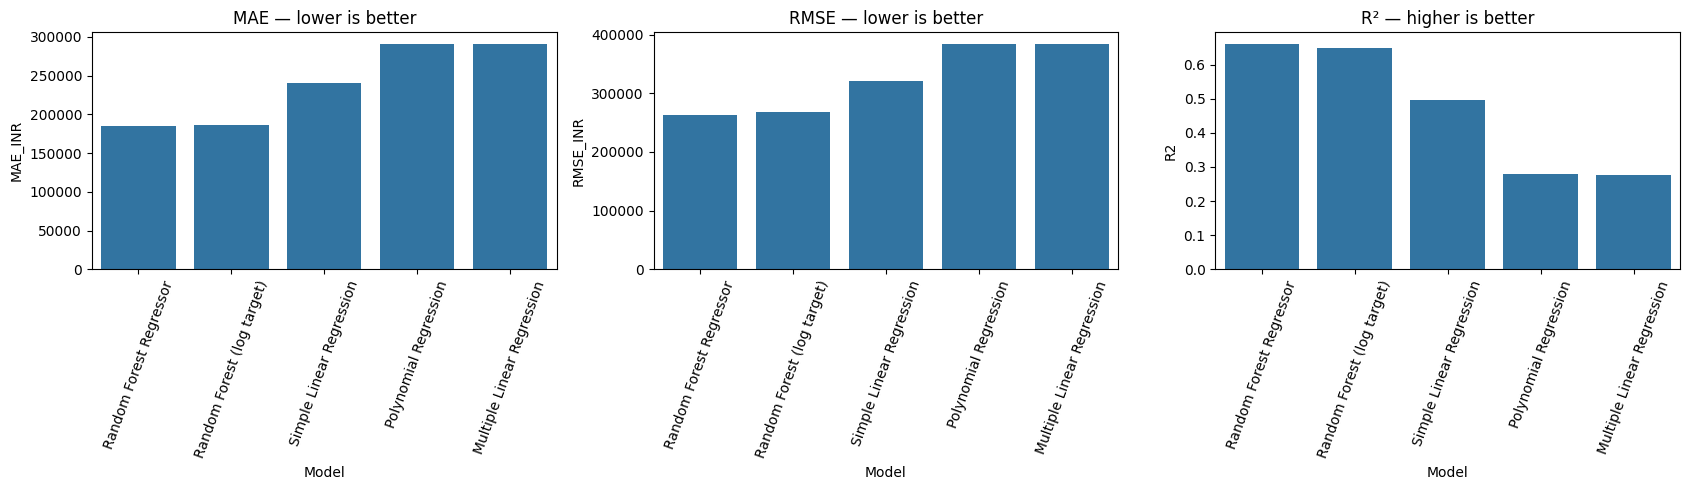

In [35]:
fig, ax = plt.subplots(1,3,figsize=(17,5))
sns.barplot(data=regression_comparison, x="Model", y="MAE_INR", ax=ax[0])
ax[0].set_title("MAE — lower is better")
sns.barplot(data=regression_comparison, x="Model", y="RMSE_INR", ax=ax[1])
ax[1].set_title("RMSE — lower is better")
sns.barplot(data=regression_comparison, x="Model", y="R2", ax=ax[2])
ax[2].set_title("R² — higher is better")
for a in ax:
    a.tick_params(axis="x", rotation=70)
plt.tight_layout()
plt.show()

## 9. Select the Best Model and Explain Why
Primary selection criterion: lowest MAE (typical absolute prediction error in INR). RMSE is used as a secondary criterion because it penalizes large errors. R² describes explained variance and is not called accuracy.

Selected model: Random Forest Regressor
Selection reason: lowest held-out MAE; RMSE is the secondary comparison.
MAE_INR: ₹184,628.20
MSE_INR2: 69229085905.5020
RMSE_INR: ₹263,114.21
R2: 0.6619


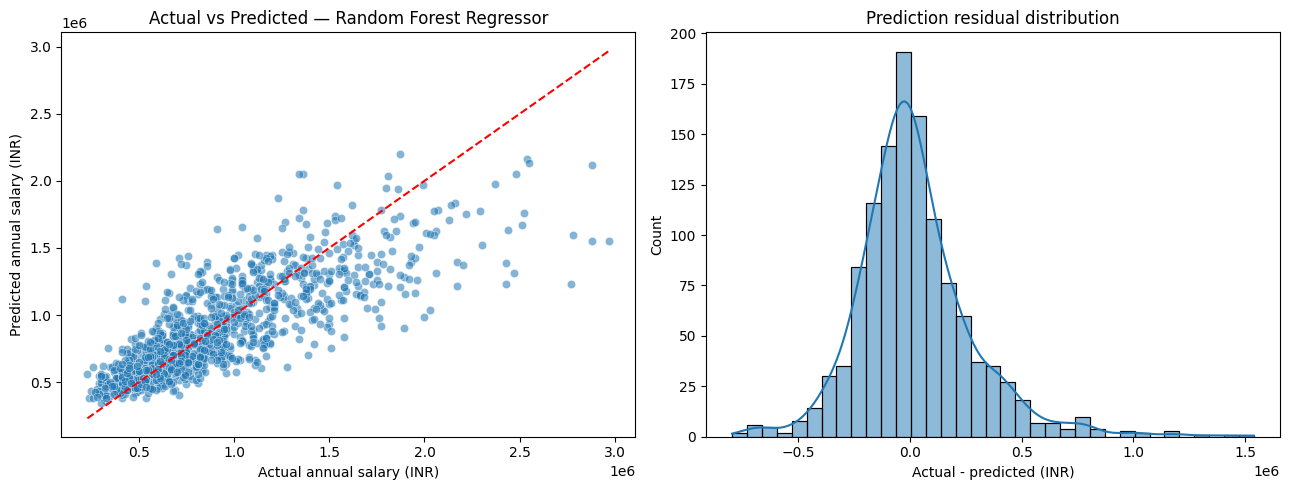

In [36]:
best_salary_name = regression_comparison.iloc[0]["Model"]
best_salary_model = fitted_regressors[best_salary_name]
if best_salary_name == "Simple Linear Regression":
    best_predictions = best_salary_model.predict(X_test_simple)
else:
    best_predictions = best_salary_model.predict(X_test)

best_salary_metrics = regression_metrics(y_test, best_predictions)
print("Selected model:", best_salary_name)
print("Selection reason: lowest held-out MAE; RMSE is the secondary comparison.")
for metric, value in best_salary_metrics.items():
    if metric.endswith("_INR"):
        print(f"{metric}: ₹{value:,.2f}")
    else:
        print(f"{metric}: {value:.4f}")

fig, ax = plt.subplots(1,2,figsize=(13,5))
sns.scatterplot(x=y_test, y=best_predictions, alpha=.55, ax=ax[0])
low=min(float(y_test.min()),float(np.min(best_predictions)))
high=max(float(y_test.max()),float(np.max(best_predictions)))
ax[0].plot([low,high],[low,high],"r--")
ax[0].set_title(f"Actual vs Predicted — {best_salary_name}")
ax[0].set_xlabel("Actual annual salary (INR)")
ax[0].set_ylabel("Predicted annual salary (INR)")
residuals = y_test - best_predictions
sns.histplot(residuals, bins=35, kde=True, ax=ax[1])
ax[1].set_title("Prediction residual distribution")
ax[1].set_xlabel("Actual - predicted (INR)")
plt.tight_layout()
plt.show()

## 10. Cross-Validation for Selected Model
Cross-validation is performed on training data. The simple regression model has a different one-column input, so it is handled separately.

In [49]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
if best_salary_name == "Simple Linear Regression":
    cv_mae = -cross_val_score(best_salary_model, X_train_simple, y_train,
                              cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
else:
    cv_mae = -cross_val_score(best_salary_model, X_train, y_train,
                              cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
print("5-fold training CV MAE (INR):", np.round(cv_mae,2))
print("Mean CV MAE (INR): ₹", f"{cv_mae.mean():,.2f}")
print("Std CV MAE (INR): ₹", f"{cv_mae.std():,.2f}")

KeyboardInterrupt: 

## 11. Save Best Model, Processed Data and Results

In [50]:
# Standardize inference input to the same feature columns.
if best_salary_name == "Simple Linear Regression":
    # Store a small wrapper-style metadata note; the API must send only experience_midpoint.
    saved_feature_note = {"input_features": ["experience_midpoint"]}
else:
    saved_feature_note = {"input_features": FEATURES}

joblib.dump(best_salary_model, os.path.join(MODEL_DIR,"salary_prediction_best.joblib"))
reg.to_csv(os.path.join(PROCESSED_DIR,"salary_prediction_processed.csv"),index=False)
regression_comparison.to_csv(os.path.join(RESULTS_DIR,"salary_model_comparison.csv"),index=False)

summary = {
    "agent": "Salary Prediction",
    "selected_model": best_salary_name,
    "selection_rule": "lowest test MAE; RMSE secondary",
    "test_metrics": best_salary_metrics,
    "cross_validation_mae_mean_inr": float(cv_mae.mean()),
    "cross_validation_mae_std_inr": float(cv_mae.std()),
    "target": TARGET,
    "target_unit": "annual INR",
    "dataset_type": "synthetic academic dataset",
    "input_note": saved_feature_note
}
with open(os.path.join(RESULTS_DIR,"salary_summary.json"),"w") as f:
    json.dump(summary,f,indent=2,default=float)
print("Saved best salary model:", best_salary_name)
print("Saved artifacts under:", BASE_DIR)

NameError: name 'cv_mae' is not defined

## 12. Test a New Salary Estimate
Use the selected model's exact input structure. The prediction is an estimate learned from synthetic training data.

In [51]:
sample = pd.DataFrame([{
    "job_text": "Data Scientist Python SQL Machine Learning Statistics",
    "location": "Bengaluru",
    "experience_level": "Mid Level",
    "experience_midpoint": 3.0,
    "experience_range": 2.0,
    "is_zero_experience": 0
}])
if best_salary_name == "Simple Linear Regression":
    sample_input = sample[["experience_midpoint"]]
else:
    sample_input = sample[FEATURES]
predicted_salary = float(best_salary_model.predict(sample_input)[0])
print(f"Estimated annual salary: ₹{predicted_salary:,.0f}")

Estimated annual salary: ₹1,046,440
